# Survival Lab

We've looked at normal-linear regression and probit regression from a likelihood perspective, which yields two log-likelihoods:
$$
LL(\beta,\sigma) = - n \log( \sqrt{2\pi} ) - n \log(\sigma) - \frac{1}{2\sigma^2} \sum_{i=1}^n (y_i - x_i \beta)^2
$$
and
$$
LL(\beta) = \sum_{i=1}^N y_i \log(\Phi(x_i \cdot \beta/\sigma)) + (1-y_i) \log(1-\Phi(x_i \cdot \beta/\sigma)).
$$
This lab combines them by looking at **right-censored** survival data.

We are going to use the Metabric breast cancer dataset to predict how long someone survives after being treated for breast cancer. For the regressions that follow, include the following as numeric variables:

- 'Age at Diagnosis'
- 'Lymph nodes examined positive'
- 'Mutation Count'
- 'Tumor Size'

and the following as categorical variables (one-hot encode them):

- 'Chemotherapy'
- 'Hormone Therapy'
- 'Radio Therapy'
- 'Tumor Stage'

The outcome variable of interest is the log of `Overall Survival (Months)`, which we'll refer to as log-months.

1. Load the `./data/metabric.csv` data. Tabulate `Overall Survival Status` to see who is alive or dead at the time the study ends. Make a kernel density plot of `Overall Survival (Months)`, hued by `Overall Survival Status`, to see the difference between survival duration for those alive and those dead at the time the study ended. **Drop the observations for which `Tumor Stage` is zero.**
2. Use Scikit's `train_test_split` with a `test_size` of .2. There are two tempting -- but ultimately incorrect -- ways to handle the Survival Status issue:
    - Use the reported `Overall Survival (Months)` as the target variable
    - Drop everyone who is alive at the time the study ends
Run these flawed regressions and save the coefficients and test-set predictions. Explain clearly how the first option is an example of imputation and the second treats survival as missing data.
3. Derive the log-likelihood for a model where the normal density is used for log-months when the subject died during the study (and log-months is observed, as in linear-normal regression), and the survival probability based on the Normal distribution is used when the patient is alive when the study ends (and log-months is a latent variable, as in a binary probit).
4. We want to estimate the model in part 3. You can do this with the `lifelines` package's `LogNormalAFTFitter`, or use the code chunk below to extend StatsModels to estimate this kind of model.
5. Compare the coefficients and test-set predictions (be careful to keep an eye on the censoring) for the censored MLE and the two linear models. Can you identify any groups who receive systematically biased predictions from the imputation and missing data approaches? 

In [38]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.base.model import GenericLikelihoodModel
from scipy.stats import norm
from lifelines import LogNormalAFTFitter

metabric = pd.read_csv("./data/metabric.csv")
metabric = metabric.loc[metabric['Tumor Stage'] != 0] # Removing stage 0 tumors

In [39]:
numerics = ['Age at Diagnosis', 'Lymph nodes examined positive',
            'Mutation Count', 'Tumor Size']
cats = ['Chemotherapy', 'Hormone Therapy', 'Radio Therapy',
        'Tumor Stage']
cols = numerics + cats + ["Overall Survival (Months)", "Overall Survival Status"]

metabric = metabric[cols].dropna()

### Part 1

We tabulate `Overall Survival Status`.

In [40]:
metabric['Overall Survival Status'].value_counts()

Overall Survival Status
1:DECEASED    768
0:LIVING      573
Name: count, dtype: int64

768 patients were deceased at the time the study ended, and 573 patients were alive. This means about 57% were deceased versus 43% alive.

We now make a kernel density plot of `Overall Survival (Months)`, hued by `Overall Survival Status`.

[Text(0.5, 1.0, 'Log of Overall Survival (Months)'),
 Text(0.5, 0, 'Log Months'),
 Text(0, 0.5, 'Density')]

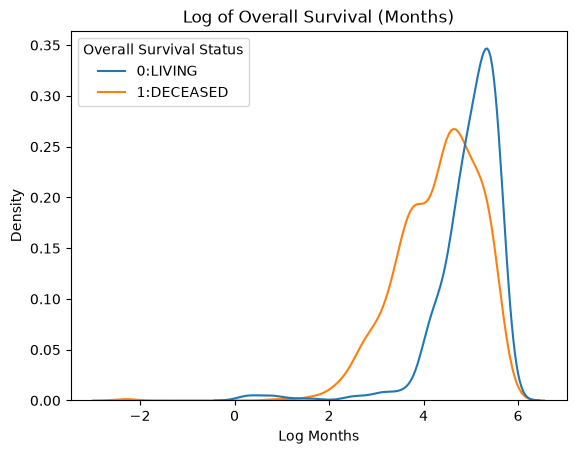

In [41]:
sns.kdeplot(data = metabric, x=np.log(metabric['Overall Survival (Months)']), hue='Overall Survival Status').set(
    title='Log of Overall Survival (Months)', xlabel='Log Months', ylabel='Density')

Looking at the plot, we see the curve representing the KDE of the deceased patients at the end of the experiment lies to the left of the curve for living patients. We see the deceased line has more area under the curve for low log month values, meaning patients that died were found to survive fewer months more often then patients who lived.

### Part 2

In [42]:
train, test = train_test_split(metabric, test_size=0.2, random_state=42)

First the model using the reported `Overall Survival (Months)` as the response variable. We save the coefficients and the predicted values.

In [43]:
model1 = smf.ols(
    'Q("Overall Survival (Months)") ~ Q("Age at Diagnosis") + Q("Lymph nodes examined positive") + ' \
    'Q("Mutation Count") + Q("Tumor Size") + C(Q("Chemotherapy")) + C(Q("Hormone Therapy")) + C(Q("Radio Therapy")) +' \
    'C(Q("Tumor Stage"))',
    data=train,
).fit()

# Saving the coefficients and test set predictions
coef1 = model1.params
pred1 = model1.predict(test)

model1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                  OLS Regression Results                                  
==========================================================================================
Dep. Variable:     Q("Overall Survival (Months)")   R-squared:                       0.140
Model:                                        OLS   Adj. R-squared:                  0.132
Method:                             Least Squares   F-statistic:                     17.28
Date:                            Wed, 18 Nov 2026   Prob (F-statistic):           2.38e-29
Time:                                    23:54:44   Log-Likelihood:                -6118.0
No. Observations:                            1072   AIC:                         1.226e+04
Df Residuals:                                1061   BIC:                         1.231e+04
Df Model:                                      10                                         
Covariance Type:                        nonrobust                                         
======================================================================================================
                                         coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------------
Intercept                            217.1385     13.578     15.992      0.000     190.495     243.782
C(Q("Chemotherapy"))[T.YES]          -30.3526      7.021     -4.323      0.000     -44.129     -16.576
C(Q("Hormone Therapy"))[T.YES]        -8.3292      5.100     -1.633      0.103     -18.336       1.677
C(Q("Radio Therapy"))[T.YES]           8.0610      4.970      1.622      0.105      -1.692      17.814
C(Q("Tumor Stage"))[T.2.0]           -11.8321      5.758     -2.055      0.040     -23.130      -0.534
C(Q("Tumor Stage"))[T.3.0]           -24.9786     11.329     -2.205      0.028     -47.209      -2.748
C(Q("Tumor Stage"))[T.4.0]           -31.9534     33.721     -0.948      0.344     -98.121      34.214
Q("Age at Diagnosis")                 -0.9937      0.203     -4.895      0.000      -1.392      -0.595
Q("Lymph nodes examined positive")    -3.0062      0.683     -4.401      0.000      -4.347      -1.666
Q("Mutation Count")                    0.7666      0.584      1.313      0.190      -0.379       1.913
Q("Tumor Size")                       -0.4333      0.199     -2.182      0.029      -0.823      -0.044
==============================================================================
Omnibus:                       66.287   Durbin-Watson:                   2.034
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               30.205
Skew:                           0.201   Prob(JB):                     2.76e-07
Kurtosis:                       2.283   Cond. No.                     1.02e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.02e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

Now we fit again after dropping everyone who is alive at the end of the study.

In [44]:
train_dead = train.loc[train['Overall Survival Status'] == '1:DECEASED']
test_dead = test.loc[test['Overall Survival Status'] == '1:DECEASED']

model2 = smf.ols(
    'np.log(Q("Overall Survival (Months)")) ~ Q("Age at Diagnosis") + Q("Lymph nodes examined positive") + ' \
    'Q("Mutation Count") + Q("Tumor Size") + C(Q("Chemotherapy")) + C(Q("Hormone Therapy")) + C(Q("Radio Therapy")) +' \
    'C(Q("Tumor Stage"))',
    data=train_dead,
).fit()

# Saving the coefficients and test set predictions
coef2 = model2.params
pred2 = model2.predict(test_dead)

model2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                      OLS Regression Results                                      
==================================================================================================
Dep. Variable:     np.log(Q("Overall Survival (Months)"))   R-squared:                       0.152
Model:                                                OLS   Adj. R-squared:                  0.138
Method:                                     Least Squares   F-statistic:                     10.81
Date:                                    Wed, 18 Nov 2026   Prob (F-statistic):           5.18e-17
Time:                                            23:54:44   Log-Likelihood:                -764.43
No. Observations:                                     615   AIC:                             1551.
Df Residuals:                                         604   BIC:                             1600.
Df Model:                                              10                                         
Covariance Type:                                nonrobust                                         
======================================================================================================
                                         coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------------
Intercept                              4.6594      0.219     21.301      0.000       4.230       5.089
C(Q("Chemotherapy"))[T.YES]           -0.3931      0.113     -3.490      0.001      -0.614      -0.172
C(Q("Hormone Therapy"))[T.YES]         0.2423      0.080      3.037      0.002       0.086       0.399
C(Q("Radio Therapy"))[T.YES]           0.0392      0.074      0.532      0.595      -0.106       0.184
C(Q("Tumor Stage"))[T.2.0]            -0.2238      0.089     -2.501      0.013      -0.400      -0.048
C(Q("Tumor Stage"))[T.3.0]            -0.5528      0.156     -3.544      0.000      -0.859      -0.246
C(Q("Tumor Stage"))[T.4.0]            -1.0499      0.436     -2.407      0.016      -1.906      -0.193
Q("Age at Diagnosis")                 -0.0029      0.003     -0.946      0.345      -0.009       0.003
Q("Lymph nodes examined positive")    -0.0279      0.009     -3.124      0.002      -0.046      -0.010
Q("Mutation Count")                    0.0096      0.008      1.209      0.227      -0.006       0.025
Q("Tumor Size")                       -0.0018      0.003     -0.692      0.489      -0.007       0.003
==============================================================================
Omnibus:                      210.630   Durbin-Watson:                   1.891
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1313.803
Skew:                          -1.375   Prob(JB):                    5.14e-286
Kurtosis:                       9.611   Cond. No.                         912.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

The first option is an example of imputation because we are essentially replacing the log-month values with the recorded number of months survived. The second treats survival as missing data since it removes all rows for patients that were alive at the end of the test, just like how we would remove missing values so they do not mess with our results.

### Part 3

For patients that died during the study, we use the normal density:
$$
f(x_i | \beta, \sigma) = \frac{1}{\sigma \sqrt{2\pi}} \exp\left(-\frac{(x_i - \beta)^2}{2\sigma^2} \right)
$$
I will call this $P_D$. For patients that were alive when the study ended, we use the survival probability based on the Normal distribution:
$$
P(y = 1 | x) = \Phi(x_i \cdot \beta/\sigma)
$$
I will call this $P_A$. The likelihood is the joint density of the data under independence. Lets say $d$ is the number of deceased patients in a given sample. We can then write the likelihood of this model as the product of the densities. We take the product of the deceased density raised to the power of $d$, and the alive density raised to the power of $1 - d$. This would look like:
$$
L(\beta) = \prod_{i=1}^{n} (P_D)^d \cdot (P_A)^{1-d}
$$
We can then derive the log-likelihood for this model by taking the log of our likelihood equation using the given log-likelihood formulas at the beginning of this assignment: 
$$\begin{aligned}
LL(\beta, \sigma) &= \log\left(\prod_{i=1}^{n} (P_D)^d \cdot (P_A)^{1-d}\right) \\
          &= \log\left(\prod_{i=1}^{n} \left(\frac{1}{\sigma \sqrt{2\pi}} \exp\left(-\frac{(x_i - \beta)^2}{2\sigma^2} \right)\right)^d \cdot (\Phi(x_i \cdot \beta/\sigma))^{1-d}\right) \\
          &= \sum_{i=1}^{n} \log\left(\prod_{i=1}^{n} \left(\frac{1}{\sigma \sqrt{2\pi}} \exp\left(-\frac{(x_i - \beta)^2}{2\sigma^2} \right)\right)^d \cdot (\Phi(x_i \cdot \beta/\sigma))^{1-d}\right) \\
          &= \sum_{i=1}^{n} \log\left(\prod_{i=1}^{n} \left(\frac{1}{\sigma \sqrt{2\pi}} \exp\left(-\frac{(x_i - \beta)^2}{2\sigma^2} \right)\right)^d\right) + \log(\Phi(x_i \cdot \beta/\sigma))^{1-d}) \\
          &= \sum_{i=1}^{n} - n \log( \sqrt{2\pi} ) - n \log(\sigma) - \frac{1}{2\sigma^2} \sum_{i=1}^n (y_i - x_i \beta)^2 + \log(\Phi(x_i \cdot \beta/\sigma)) + (1-y_i) \log(1-\Phi(x_i \cdot \beta/\sigma))
\end{aligned}$$
So the log-likelihood of the model is:
$$
LL(\beta, \sigma) = \sum_{i=1}^{n} - n \log( \sqrt{2\pi} ) - n \log(\sigma) - \frac{1}{2\sigma^2} \sum_{i=1}^n (y_i - x_i \beta)^2 + \log(\Phi(x_i \cdot \beta/\sigma)) + (1-y_i) \log(1-\Phi(x_i \cdot \beta/\sigma))
$$

**Part 4**

I will now use the given code to estimate the model in part 3.

In [45]:
class CensoredNormalMLE(GenericLikelihoodModel):
    def __init__(self, endog, exog, event):
        super().__init__(endog, exog, extra_params_names=["log_sigma"])
        self.event = np.asarray(event)

    def nloglikeobs(self, params):
        beta, log_sigma = params[:-1], params[-1]
        sigma = np.exp(log_sigma)
        z = (self.endog - self.exog @ beta) / sigma
        ll_dead = norm.logpdf(z) - log_sigma
        ll_alive = norm.logsf(z)
        return -np.where(self.event == 1, ll_dead, ll_alive)

start = np.r_[model2.params, np.log(np.sqrt(np.mean(model2.resid ** 2)))]

# One hot encoding categorical variables
event = train["Overall Survival Status"].str.startswith("1").astype(int)
X_train = pd.get_dummies(train[numerics + cats], columns=cats, drop_first=True, dtype=float)
X_train = sm.add_constant(X_train, has_constant="add")
y_train = np.log(train['Overall Survival (Months)'])

model = CensoredNormalMLE(y_train, X_train, event)
mle = model.fit(start_params=start, method="bfgs", maxiter=1000, disp=False)

print("Converged:", mle.mle_retvals["converged"])
print(mle.summary())

Converged: True
                              CensoredNormalMLE Results                              
Dep. Variable:     Overall Survival (Months)   Log-Likelihood:                -1201.4
Model:                     CensoredNormalMLE   AIC:                             2427.
Method:                   Maximum Likelihood   BIC:                             2487.
Date:                       Wed, 18 Nov 2026                                         
Time:                               23:54:44                                         
No. Observations:                       1072                                         
Df Residuals:                           1060                                         
Df Model:                                 10                                         
                                    coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

### Part 5

First comparing the coefficients:

In [46]:
coef1

Intercept                             217.138496
C(Q("Chemotherapy"))[T.YES]           -30.352639
C(Q("Hormone Therapy"))[T.YES]         -8.329212
C(Q("Radio Therapy"))[T.YES]            8.061039
C(Q("Tumor Stage"))[T.2.0]            -11.832086
C(Q("Tumor Stage"))[T.3.0]            -24.978649
C(Q("Tumor Stage"))[T.4.0]            -31.953377
Q("Age at Diagnosis")                  -0.993668
Q("Lymph nodes examined positive")     -3.006212
Q("Mutation Count")                     0.766640
Q("Tumor Size")                        -0.433314
dtype: float64

In [52]:
coef2

Intercept                             4.659419
C(Q("Chemotherapy"))[T.YES]          -0.393093
C(Q("Hormone Therapy"))[T.YES]        0.242348
C(Q("Radio Therapy"))[T.YES]          0.039192
C(Q("Tumor Stage"))[T.2.0]           -0.223816
C(Q("Tumor Stage"))[T.3.0]           -0.552826
C(Q("Tumor Stage"))[T.4.0]           -1.049910
Q("Age at Diagnosis")                -0.002901
Q("Lymph nodes examined positive")   -0.027944
Q("Mutation Count")                   0.009611
Q("Tumor Size")                      -0.001833
dtype: float64

In [48]:
coef3 = pd.Series(mle.params, index=['const', 'Age at Diagnosis', 'Lymph nodes examined positive', 
                                     'Mutation Count', 'Tumor Size', 'Chemotherapy_YES', 'Hormone Therapy_YES',
                                     'Radio Therapy_YES', 'Tumor Stage_2.0', 'Tumor Stage_3.0', 'Tumor Stage_4.0',
                                     'log_sigma'])
coef3

const                            6.761230
Age at Diagnosis                -0.021836
Lymph nodes examined positive   -0.056686
Mutation Count                  -0.016831
Tumor Size                      -0.008705
Chemotherapy_YES                -0.272630
Hormone Therapy_YES              0.261282
Radio Therapy_YES                0.213519
Tumor Stage_2.0                 -0.322433
Tumor Stage_3.0                 -0.553193
Tumor Stage_4.0                 -0.846787
log_sigma                        0.083321
dtype: float64

Because model1 predicted the recorded months instead of the log months, we see very different coefficients for some of the values. It seems to put a lot of emphasis on chemotherapy and tumor stage. Model2 is a little more similar to our censored model, as most of the coefficients are about the same.

Now we compare predictions:

In [49]:
pred1

804    157.712395
550    175.906242
572    135.064581
432    147.223984
260     99.340519
          ...    
810    107.049188
682    149.132543
367    140.248738
844    122.658131
766    119.041211
Length: 269, dtype: float64

In [53]:
np.exp(pred2)

308      21.953207
505      89.952811
713      67.936946
1050     86.737835
76       78.268149
           ...    
110     113.465669
810      59.291507
367      95.667288
844      88.116670
766      88.918471
Length: 153, dtype: float64

In [17]:
X_test = pd.get_dummies(test[numerics + cats], columns=cats, drop_first=True, dtype=float)
X_test = sm.add_constant(X_test, has_constant="add")

beta = np.asarray(mle.params)[:-1]
pred3 = pd.Series(X_test.to_numpy() @ beta, index=test.index)

In [54]:
np.exp(pred3)

804    214.656449
550    270.617765
572    183.459992
432    265.734809
260    155.447567
          ...    
810    119.520591
682    150.467569
367    201.169810
844    129.259561
766    117.553484
Length: 269, dtype: float64

To compare our predicted values, I took the exponential of the predictions for models 2 and 3 so that all predictions are on the same scale. We can notice a few things. First, the predictions for model1 seem to have a wide range with some very high values and some much smaller. Comparing to the model2 predictions, we see the values all seem to be much smaller than either of the other two models. The censored model appears ot have higher predictions than the other two, but the values appear closer to eachother than in model1.

From this, it appears to me that models 1 and 2 have some bias in the predictions depending on whether a patient was alive or dead after the tests. Model1 has a wide range of values, where I am assuming the high values are patients that lived. Model2 only includes deceased patients, and the predicted values we find here are noticeably smaller.